## QUESTION 1

In [127]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as  sns

In [128]:
df = pd.read_csv("automobileEDA.csv") #importing the dataset

In [129]:
df.head()

,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1


In [130]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  201 non-null    int64  
 2   make               201 non-null    str    
 3   aspiration         201 non-null    str    
 4   num-of-doors       201 non-null    str    
 5   body-style         201 non-null    str    
 6   drive-wheels       201 non-null    str    
 7   engine-location    201 non-null    str    
 8   wheel-base         201 non-null    float64
 9   length             201 non-null    float64
 10  width              201 non-null    float64
 11  height             201 non-null    float64
 12  curb-weight        201 non-null    int64  
 13  engine-type        201 non-null    str    
 14  num-of-cylinders   201 non-null    str    
 15  engine-size        201 non-null    int64  
 16  fuel-system        201 non-null    st

In [131]:
df.shape

(201, 29)

The dataset contains 201 rows and 29 columns. The 13 continuous columns include; price,wheel-base, height, curb-weight, engine-size, bore, stroke, compression-ratio, horsepower,peak-rpm, city-mpg, highway-mpg


In [132]:
continuous = ["wheel-base", "length", "width", "height", "curb-weight", "engine-size", "bore", "stroke", "compression-ratio", "horsepower", "peak-rpm", "city-mpg", "highway-mpg", "city-L/100km"]

categorical = ["make", "aspiration", "num-of-doors", "body-style", "drive-wheels",  "engine-location", "engine-type", "num-of-cylinders", "fuel-system", "symboling", "horsepower-binned", "diesel", "gas"]

In [133]:
df[categorical].nunique()
df[continuous].describe()

,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,city-L/100km
count,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,197.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000
mean,98.797015,0.837102,0.915126,53.766667,2555.666667,126.875622,3.330692,3.256904,10.164279,103.405534,5117.665368,25.179104,30.686567,9.944145
std,6.066366,0.059213,0.029187,2.447822,517.296727,41.546834,0.268072,0.319256,4.004965,37.365700,478.113805,6.423220,6.815150,2.534599
min,86.600000,0.678039,0.837500,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,4.795918
25%,94.500000,0.801538,0.890278,52.000000,2169.000000,98.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7.833333
50%,97.000000,0.832292,0.909722,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5125.369458,24.000000,30.000000,9.791667
75%,102.400000,0.881788,0.925000,55.500000,2926.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,12.368421
max,120.900000,1.000000,1.000000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,262.000000,6600.000000,49.000000,54.000000,18.076923


In [134]:
df.isnull().sum() #checking for missing values

symboling            0
normalized-losses    0
make                 0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               4
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
city-L/100km         0
horsepower-binned    1
diesel               0
gas                  0
dtype: int64

In [135]:
df["stroke"]= df["stroke"].fillna(df["stroke"].median()) #filling the missing data
df[df["horsepower-binned"].isnull()][["horsepower", "horsepower-binned"]]
df["horsepower-binned"] = df["horsepower-binned"].fillna("High")

Stroke had  four missing values which belonged to mazda cars. With only 201 rows, dropping would throw away data.
Median was chosen over mean  because the variable stroke is numeric and contains outliers. 

The horsepower-binned column had one missing value. Inspecting the row showed a car with 262 hp, which is above the upper limit of the "High" bin (207 hp), so it had not been assigned a category. Because this car has more horsepower than every car in the High group, I assigned it to "High". This is a logical imputation, not a guess: no other bin makes sense.

In [136]:
df.duplicated().sum() #checking for duplicates

np.int64(0)

No duplicates were found

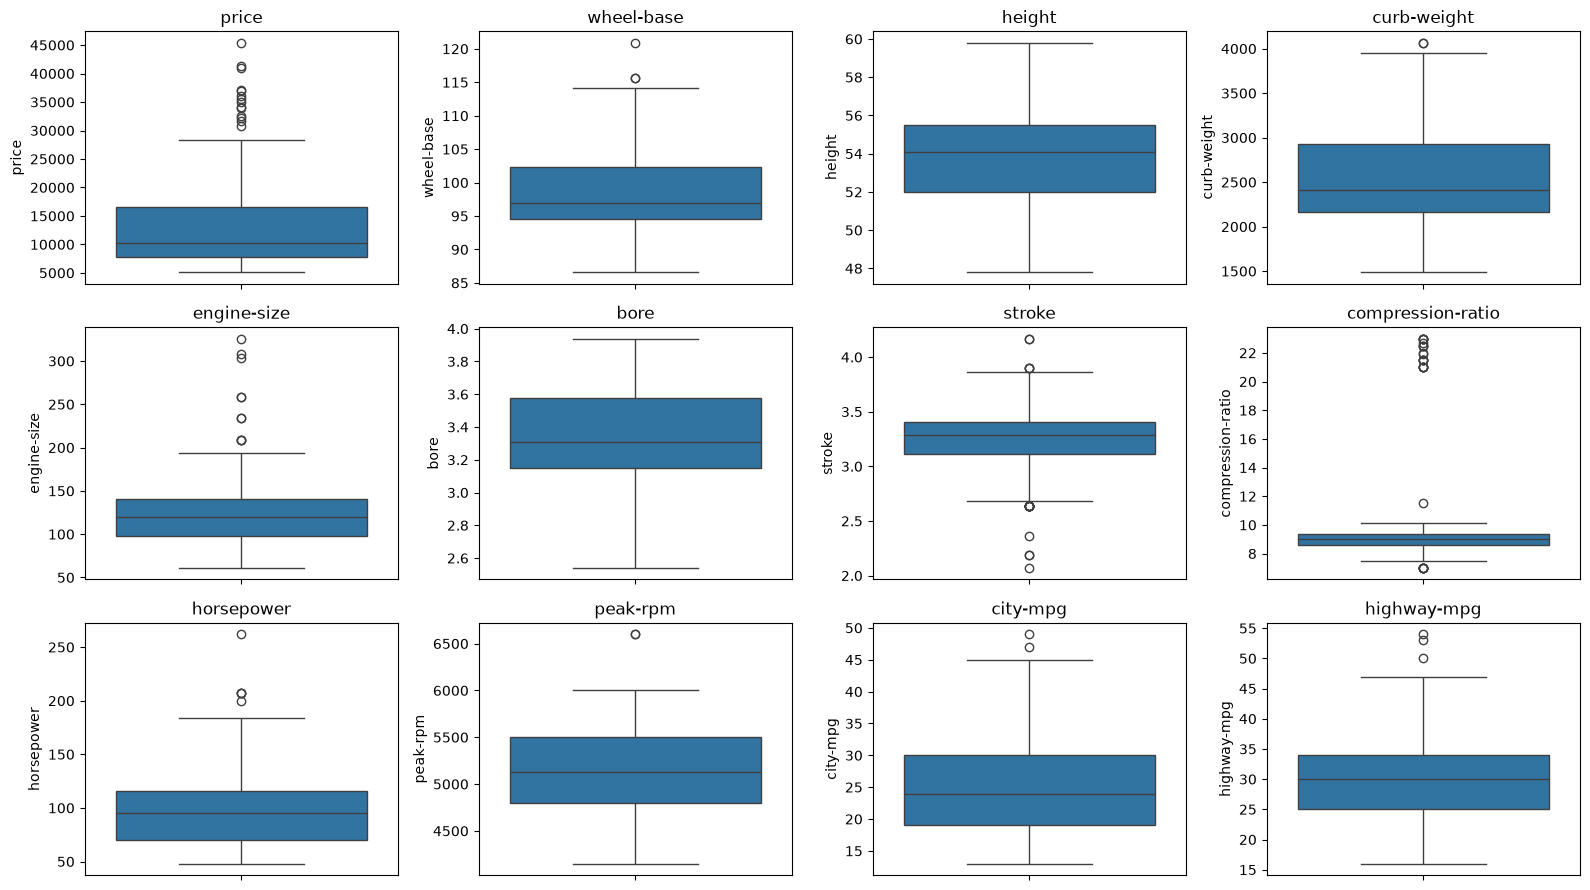

In [137]:
cont_cols = ["price", "wheel-base", "height", "curb-weight", "engine-size", "bore", "stroke", "compression-ratio", "horsepower", "peak-rpm", "city-mpg", "highway-mpg"]

fig, axes = plt.subplots(3, 4, figsize=(16, 9))

for ax, col in zip(axes.flatten(), cont_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

In [138]:
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((series < q1 - 1.5*iqr) | (series > q3 + 1.5*iqr))

outlier_counts = {col: iqr_outliers(df[col]).sum() for col in cont_cols}
pd.Series(outlier_counts, name="outliers")

price                14
wheel-base            3
height                0
curb-weight           2
engine-size          10
bore                  0
stroke               20
compression-ratio    27
horsepower            5
peak-rpm              2
city-mpg              2
highway-mpg           3
Name: outliers, dtype: int64

The IQR rule was used to count outliers. The most affected variables were compression-ratio (27), stroke (20), price (14) and engine-size (10). height and bore had none, and the remaining variables had only a few.


In [139]:
df.sort_values("price", ascending=False)[["make", "body-style", "horsepower", "engine-size", "price"]].head(5)

df[df["compression-ratio"] > 15][["make", "engine-type", "diesel", "compression-ratio"]].head()

,make,engine-type,diesel,compression-ratio
60,mazda,ohc,1,22.7
63,mazda,ohc,1,22.0
64,mercedes-benz,ohc,1,21.5
65,mercedes-benz,ohc,1,21.5
66,mercedes-benz,ohc,1,21.5


The outliers should not be dropped. They represent real vehicles, and removing them would delete exactly the luxury, high-performance cars that help explain what drives price. With only 201 rows, removing them would also reduce the sample size. 

In [140]:
print("Missing values:", df.isnull().sum().sum())   
print("Duplicates:", df.duplicated().sum())         
print("Shape:", df.shape)                           

Missing values: 0
Duplicates: 0
Shape: (201, 29)


In [141]:
df.to_csv("Immaculate_Data.csv", index=False)

In [142]:
check = pd.read_csv("Immaculate_Data.csv")
check.shape, check.isnull().sum().sum()

((201, 29), np.int64(0))

The dataset has 201 rows and 29 columns, with price as the target variable. 
I found and handled the following:

Missing values: 4 in stroke (all rotary-engine Mazdas) were filled with the median, and 1 in horsepower-binned was assigned to "High" because its horsepower (262) exceeds the High range.

Duplicates: none were found.

Outliers: detected with boxplots and the IQR rule, then inspected. They were kept because they represent genuine luxury and diesel vehicles.
The cleaned dataset has no missing values and was saved as YourLastName_Data.csv.

## QUESTION 2

In [143]:
df[continuous + ["price"]].describe().T.round(2) #for continuous variables

,count,mean,std,min,25%,50%,75%,max
wheel-base,201.0,98.80,6.07,86.60,94.50,97.00,102.40,120.90
length,201.0,0.84,0.06,0.68,0.80,0.83,0.88,1.00
width,201.0,0.92,0.03,0.84,0.89,0.91,0.92,1.00
height,201.0,53.77,2.45,47.80,52.00,54.10,55.50,59.80
curb-weight,201.0,2555.67,517.30,1488.00,2169.00,2414.00,2926.00,4066.00
engine-size,201.0,126.88,41.55,61.00,98.00,120.00,141.00,326.00
bore,201.0,3.33,0.27,2.54,3.15,3.31,3.58,3.94
stroke,201.0,3.26,0.32,2.07,3.11,3.29,3.41,4.17
compression-ratio,201.0,10.16,4.00,7.00,8.60,9.00,9.40,23.00
horsepower,201.0,103.41,37.37,48.00,70.00,95.00,116.00,262.00


The dataset has 201 complete observations for every continuous variable. Price has a mean of about 13,207 and a median of 10,295, with a standard deviation of 7,947 and a maximum of 45,400. Because the mean is well above the median, a small number of expensive cars pull the average up, so most cars are cheaper than the "average" suggests.

Engine-size (mean 127, median 120, max 326) and horsepower (mean 103, median 95, max 262) show the same pattern: typical cars have modest engines, while a few high-performance cars sit far above. Curb-weight averages about 2,556, and height (mean 53.8) and bore (mean 3.33) are fairly uniform across cars, with small standard deviations. Fuel economy averages 25 mpg in the city and 31 mpg on the highway

In [144]:
df[continuous + ["price"]].skew().round(2).sort_values() #check for skewness

stroke              -0.71
bore                -0.03
height               0.03
peak-rpm             0.11
length               0.15
highway-mpg          0.55
city-L/100km         0.59
city-mpg             0.68
curb-weight          0.71
width                0.88
wheel-base           1.03
horsepower           1.15
price                1.81
engine-size          1.98
compression-ratio    2.58
dtype: float64

## Skewness
Price is strongly right-skewed (1.81), meaning a long tail of expensive cars. Compression-ratio (2.58) and engine-size (1.98) are the most skewed, and horsepower (1.15) and wheel-base (1.03) are also clearly right-skewed. Compression-ratio is skewed mainly because the diesel cars have values above 20. Stroke is mildly left-skewed (-0.71), while bore, height, peak-rpm and length are close to symmetric (skewness near 0).

Since price is skewed, its mean is not a reliable measure of a typical car, so I will use the median alongside it in later analysis. A log transformation could be used if modelling were required.

In [145]:
for col in categorical: #frequency counts for categorical variables
    print(f"--- {col} ---")
    print(df[col].value_counts())
    print()

--- make ---
make
toyota           32
nissan           18
mazda            17
honda            13
mitsubishi       13
subaru           12
volkswagen       12
peugot           11
volvo            11
dodge             9
bmw               8
mercedes-benz     8
plymouth          7
audi              6
saab              6
porsche           4
alfa-romero       3
chevrolet         3
jaguar            3
isuzu             2
renault           2
mercury           1
Name: count, dtype: int64

--- aspiration ---
aspiration
std      165
turbo     36
Name: count, dtype: int64

--- num-of-doors ---
num-of-doors
four    115
two      86
Name: count, dtype: int64

--- body-style ---
body-style
sedan          94
hatchback      68
wagon          25
hardtop         8
convertible     6
Name: count, dtype: int64

--- drive-wheels ---
drive-wheels
fwd    118
rwd     75
4wd      8
Name: count, dtype: int64

--- engine-location ---
engine-location
front    198
rear       3
Name: count, dtype: int64

--- engine-ty

Frequency counts (categorical)

	•	Make: Toyota is the most common brand (32 cars), followed by Nissan (18) and Mazda (17). Mercury has only 1 car, and luxury brands such as Porsche (4) and Jaguar (3) are rare.
	•	Body-style: Sedans (94) and hatchbacks (68) make up about 80% of the data. Hardtops (8) and convertibles (6) are rare.
	•	Drive-wheels: Front-wheel drive dominates (118), then rear-wheel (75). Four-wheel drive has only 8 cars.
	•	Aspiration: 165 cars are standard and 36 are turbo.
	•	Num-of-doors: 115 four-door and 86 two-door.
	•	Engine-location: 198 front and only 3 rear.
	•	Engine-type: ohc is by far the most common (145).
	•	Num-of-cylinders: Four-cylinder engines dominate (157), with 24 six-cylinder cars and very few others (one car each for three and twelve cylinders).
	•	Fuel-system: mpfi (92) and 2bbl (64) are the most common.
	•	Fuel type: 181 gas and 20 diesel cars.
	•	Horsepower-binned: 115 Low, 62 Medium and 24 High (after the missing value was assigned to High).

Price Distribution graph


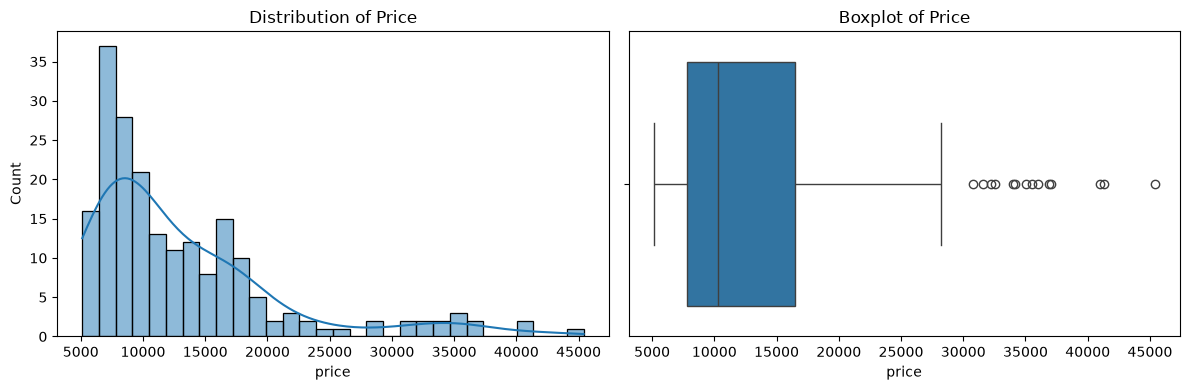

In [146]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["price"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Price")

sns.boxplot(x=df["price"], ax=axes[1])
axes[1].set_title("Boxplot of Price")

plt.tight_layout()
plt.show()

# Interpretation
The price histogram is right-skewed: most cars cost between roughly 6,000 and 17,000, with a long tail up to 45,400. The boxplot confirms this, with the expensive cars shown as outliers above the upper whisker. This matches the skewness of 1.81 and the mean (13,207) being above the median (10,295).

# Histograms of continuous variables


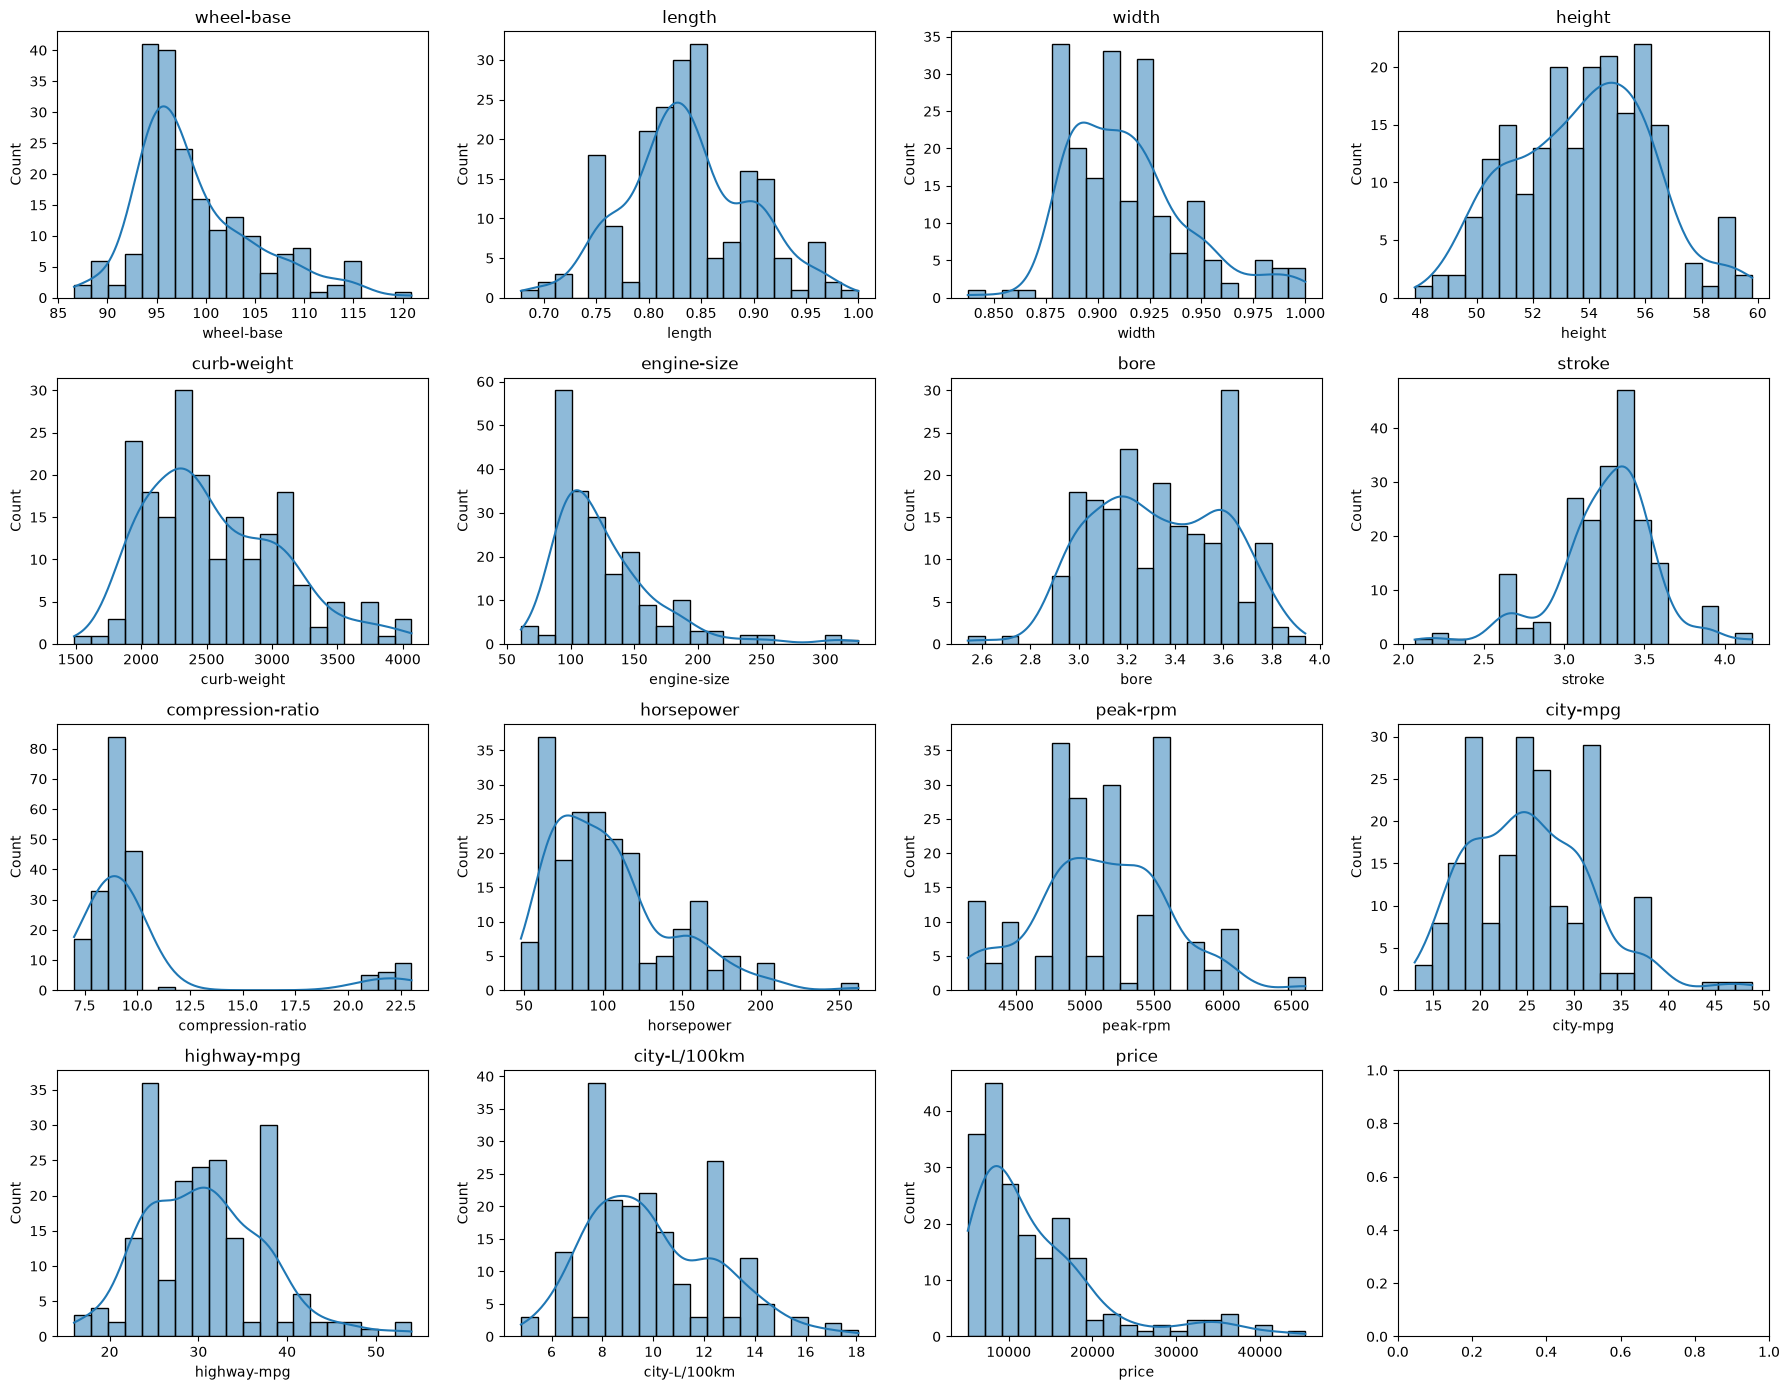

In [147]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.flatten(), continuous + ["price"]):
    sns.histplot(df[col], bins=20, kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Engine-size, horsepower and compression-ratio are right-skewed, with a few very large values. Compression-ratio has two clusters: a main group around 9 and a small group above 20 (diesel cars). Curb-weight, wheel-base and width are mildly right-skewed. Bore, height and peak-rpm are roughly symmetric. City-mpg and highway-mpg are right-skewed, with most cars in the 20 to 35 mpg range

# Bar charts for categorical variables


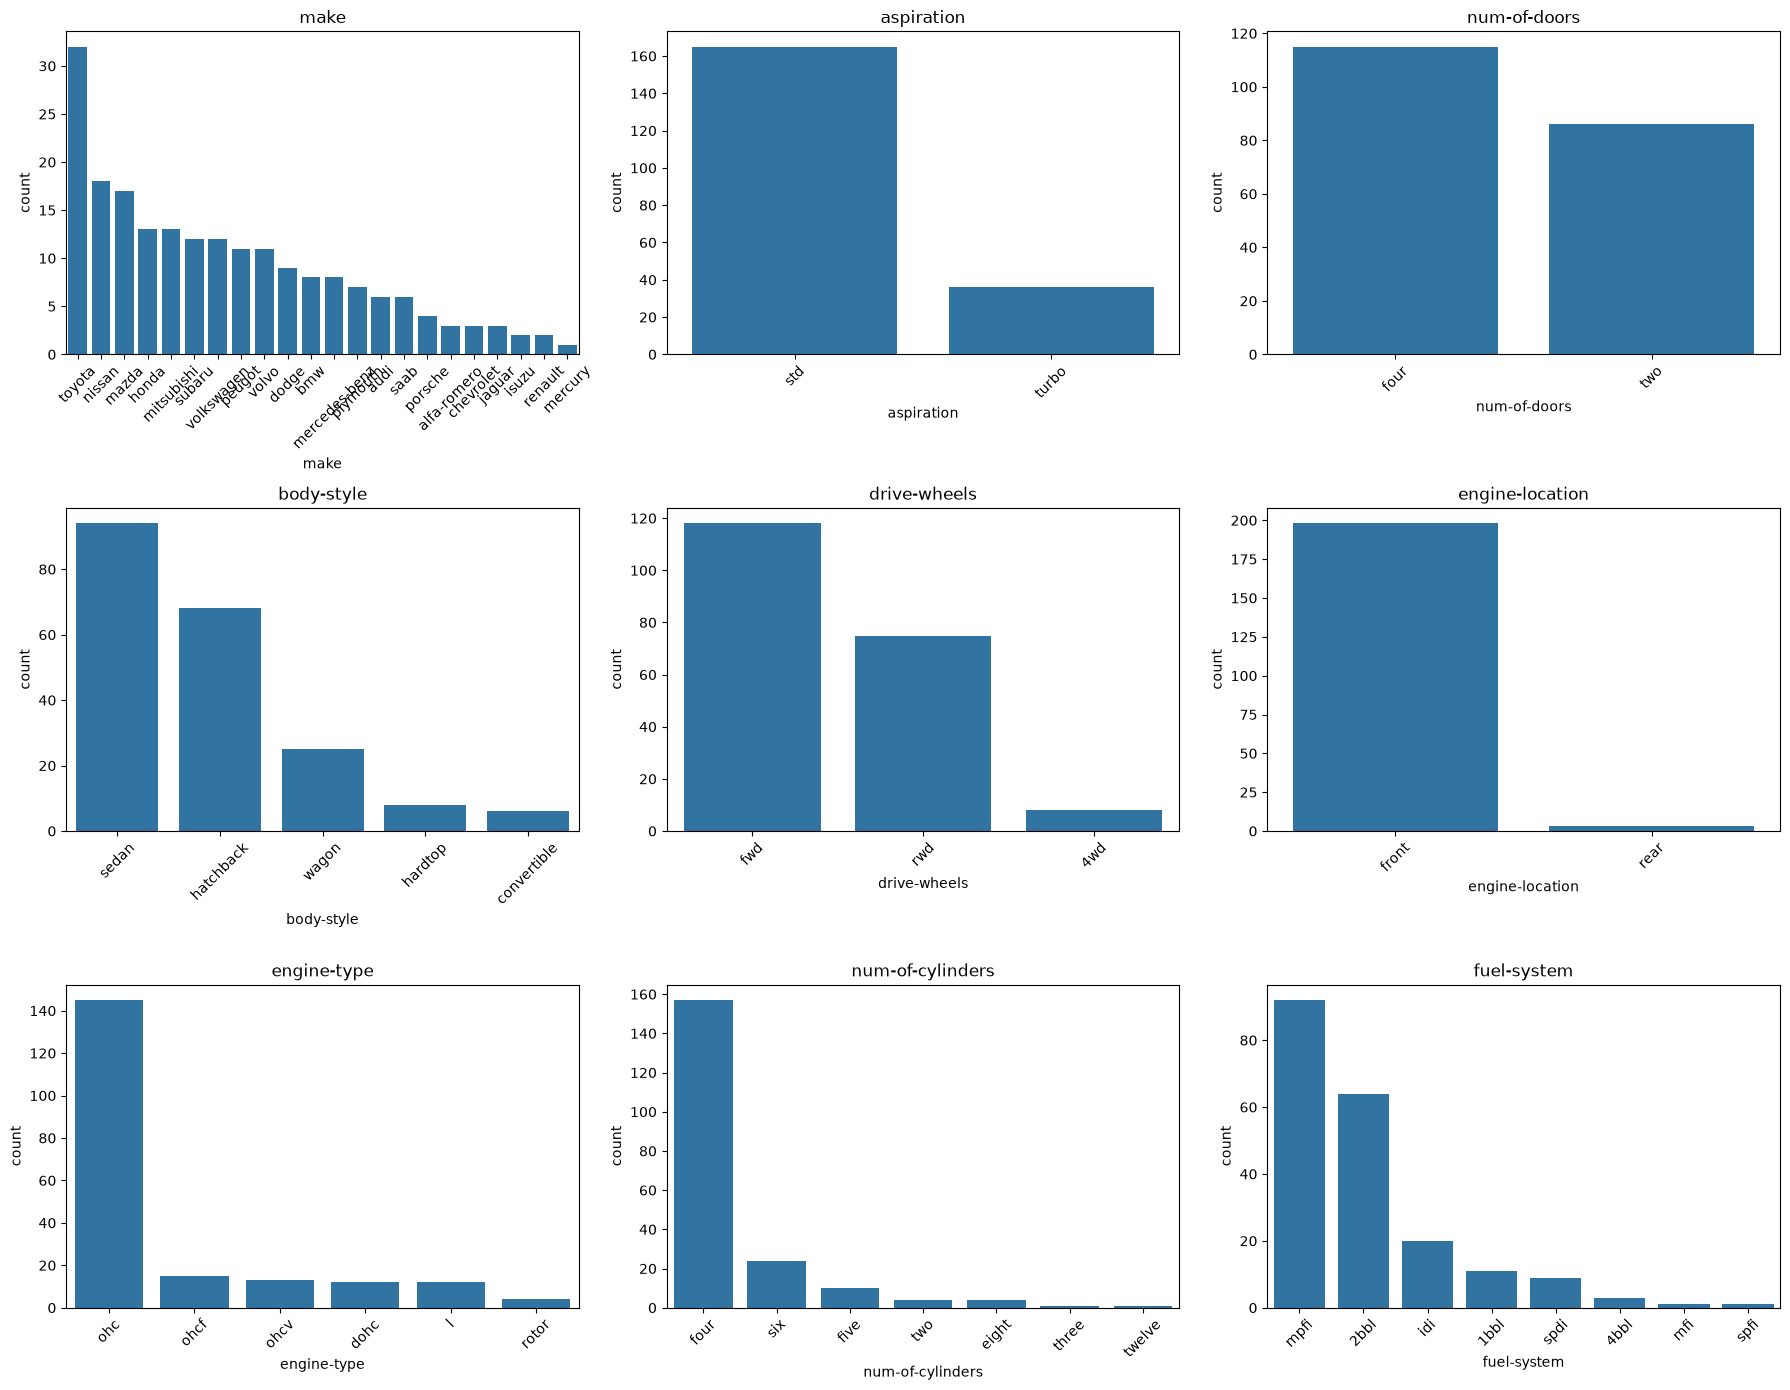

In [148]:
cat_plot = ["make", "aspiration", "num-of-doors", "body-style", "drive-wheels",
            "engine-location", "engine-type", "num-of-cylinders", "fuel-system"]

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.flatten(), cat_plot):
    sns.countplot(x=col, data=df, order=df[col].value_counts().index, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

The bar charts confirm that the categories are unbalanced: sedans and hatchbacks dominate body-style, front-wheel drive dominates drive-wheels, and most cars have front engines, four cylinders and ohc engines. Toyota is the most frequent make.


Summary of patterns: 
* Price is right-skewed, with most cars being affordable and a few luxury ones very expensive. 
* Engine-size, horsepower and compression-ratio are also right-skewed, which hints they may be related to price. 
* The categorical data is heavily concentrated in a few categories (sedan/hatchback, fwd, four-cylinder, front engine), so rare groups need cautious interpretation.

## QUESTION 3: Group by parameters and compare average price


**Group by driver wheels**


In [149]:
dw = df.groupby("drive-wheels")["price"].agg(["mean", "median", "count"]).round(0)
dw = dw.sort_values("mean")
dw # drive wheels

,mean,median,count
drive-wheels,,,
fwd,9245.0,8192.0,118
4wd,10241.0,9006.0,8
rwd,19758.0,16900.0,75


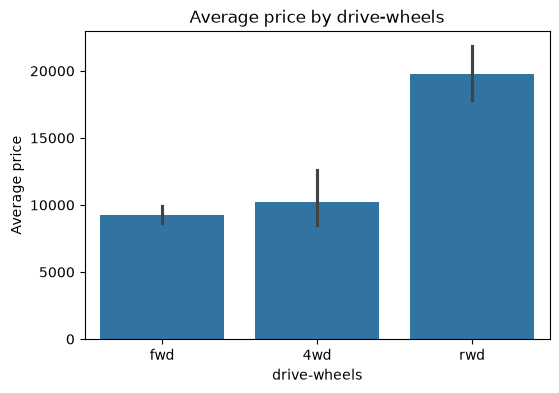

In [150]:
plt.figure(figsize=(6, 4))
sns.barplot(x="drive-wheels", y="price", data=df, estimator="mean", order=dw.index)
plt.title("Average price by drive-wheels")
plt.ylabel("Average price")
plt.show()

**Interpretation for drive-wheels:**

Rear-wheel-drive (rwd) cars have the highest average price (about 19,758), nearly double front-wheel-drive (fwd) cars, which have the lowest (about 9,245). Four-wheel drive averages about 10,241, close to fwd, but it is based on only 8 cars, so it should be treated with caution. The medians (rwd 16,900; fwd 8,192) show the same ranking, so the result is not driven by a few extreme cars. Rwd is typical of luxury, sports and performance cars, which explains the higher prices.

**Group by body Style**


In [151]:
bs = df.groupby("body-style")["price"].agg(["mean", "median", "count"]).round(0)
bs = bs.sort_values("mean")
bs

,mean,median,count
body-style,,,
hatchback,9957.0,8672.0,68
wagon,12372.0,11694.0,25
sedan,14460.0,11078.0,94
convertible,21890.0,17084.0,6
hardtop,22208.0,19688.0,8


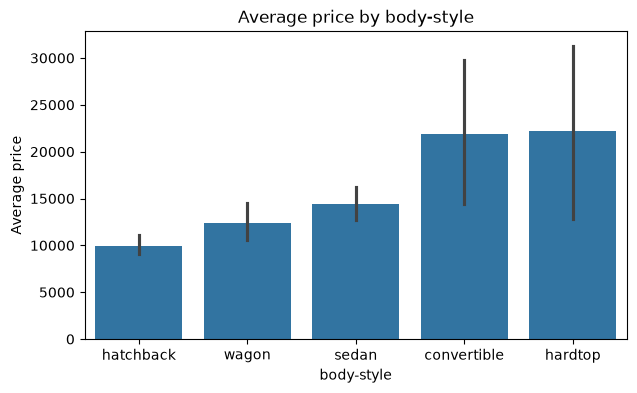

In [152]:
plt.figure(figsize=(7, 4))
sns.barplot(x="body-style", y="price", data=df, estimator="mean", order=bs.index)
plt.title("Average price by body-style")
plt.ylabel("Average price")
plt.show()

**Interpretation for body-style:**

Hardtops (about 22,208) and convertibles (about 21,890) have the highest average prices, followed by sedans (about 14,460) and wagons (about 12,372). Hatchbacks are the cheapest (about 9,957). Hardtops and convertibles are premium, low-volume body styles, but they have only 8 and 6 cars, so their averages are less reliable. Sedans have a mean well above their median (11,078), meaning a few luxury sedans pull the average up.

**Group by both driver wheels and body Style**


In [153]:
combo = df.groupby(['drive-wheels', 'body-style'])['price'].agg(['mean','median', 'count']).round(0)
print(combo.sort_values('mean'))

                             mean   median  count
drive-wheels body-style                          
4wd          hatchback     7603.0   7603.0      1
fwd          hardtop       8249.0   8249.0      1
             hatchback     8396.0   7689.0     49
4wd          wagon         9096.0   8396.0      4
fwd          sedan         9812.0   8558.0     55
             wagon         9997.0   8921.0     12
             convertible  11595.0  11595.0      1
4wd          sedan        12647.0  11259.0      3
rwd          hatchback    14338.0  14645.0     18
             wagon        16994.0  16515.0      9
             sedan        21712.0  18382.0     36
             convertible  23950.0  17669.0      5
             hardtop      24203.0  28176.0      7


body-style    convertible       hardtop     hatchback         sedan  \
drive-wheels                                                          
4wd                   NaN           NaN   7603.000000  12647.333333   
fwd               11595.0   8249.000000   8396.387755   9811.800000   
rwd               23949.6  24202.714286  14337.777778  21711.833333   

body-style           wagon  
drive-wheels                
4wd            9095.750000  
fwd            9997.333333  
rwd           16994.222222  


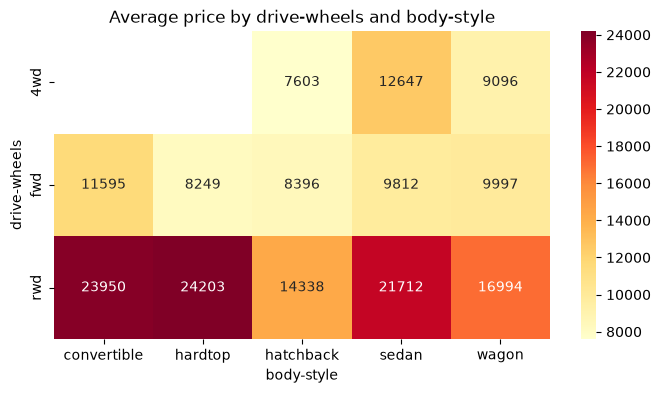

In [154]:

pivot = df.pivot_table(values="price", index="drive-wheels", columns="body-style", aggfunc="mean")
print (pivot)
plt.figure(figsize=(8, 4))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("Average price by drive-wheels and body-style")
plt.show()

**Interpretation for both body-style and drive-wheels:**

The combination analysis shows that drive-wheels matters within each body style. For example, rwd sedans average about 21,712, while fwd sedans average only about 9,812. The most expensive groups are rwd hardtop (about 24,203) and rwd convertible (about 23,950). The cheapest are 4wd hatchback and fwd hardtop, but each has a single car, so they aren't meaningful. Among well-represented groups, fwd hatchback (about 8,396, 49 cars) is the cheapest. This suggests that drive type affects price more than body style.





**Highest Price:** rwd drive-wheels, hardtop and convertible body styles (rwd hardtop overall). 

**Lowest Price:** fwd drive-wheels, hatchback body style (fwd hatchback overall, among groups with a meaningful sample).

## **QUESTION 4**

# 4a. continuous variables Vs. price

In [155]:
corr = df[continuous + ["price"]].corr()["price"].drop("price").sort_values(ascending=False)
corr.round(2)


engine-size          0.87
curb-weight          0.83
horsepower           0.81
city-L/100km         0.79
width                0.75
length               0.69
wheel-base           0.58
bore                 0.54
height               0.14
stroke               0.08
compression-ratio    0.07
peak-rpm            -0.10
city-mpg            -0.69
highway-mpg         -0.70
Name: price, dtype: float64

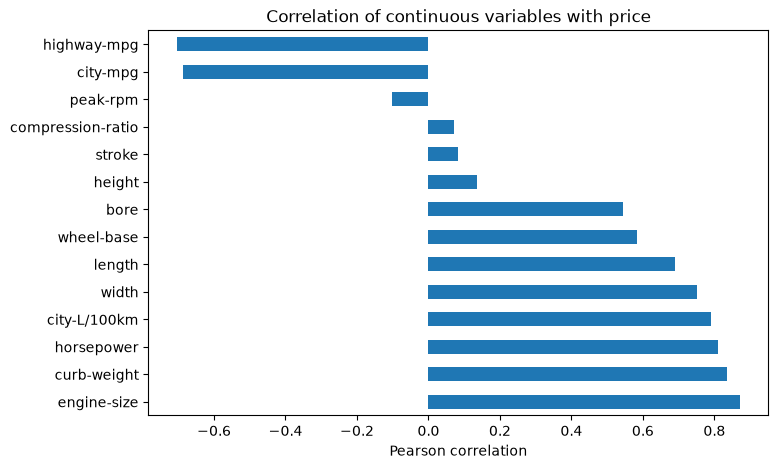

In [156]:
plt.figure(figsize=(8, 5))
corr.plot(kind="barh")
plt.title("Correlation of continuous variables with price")
plt.xlabel("Pearson correlation")
plt.show()

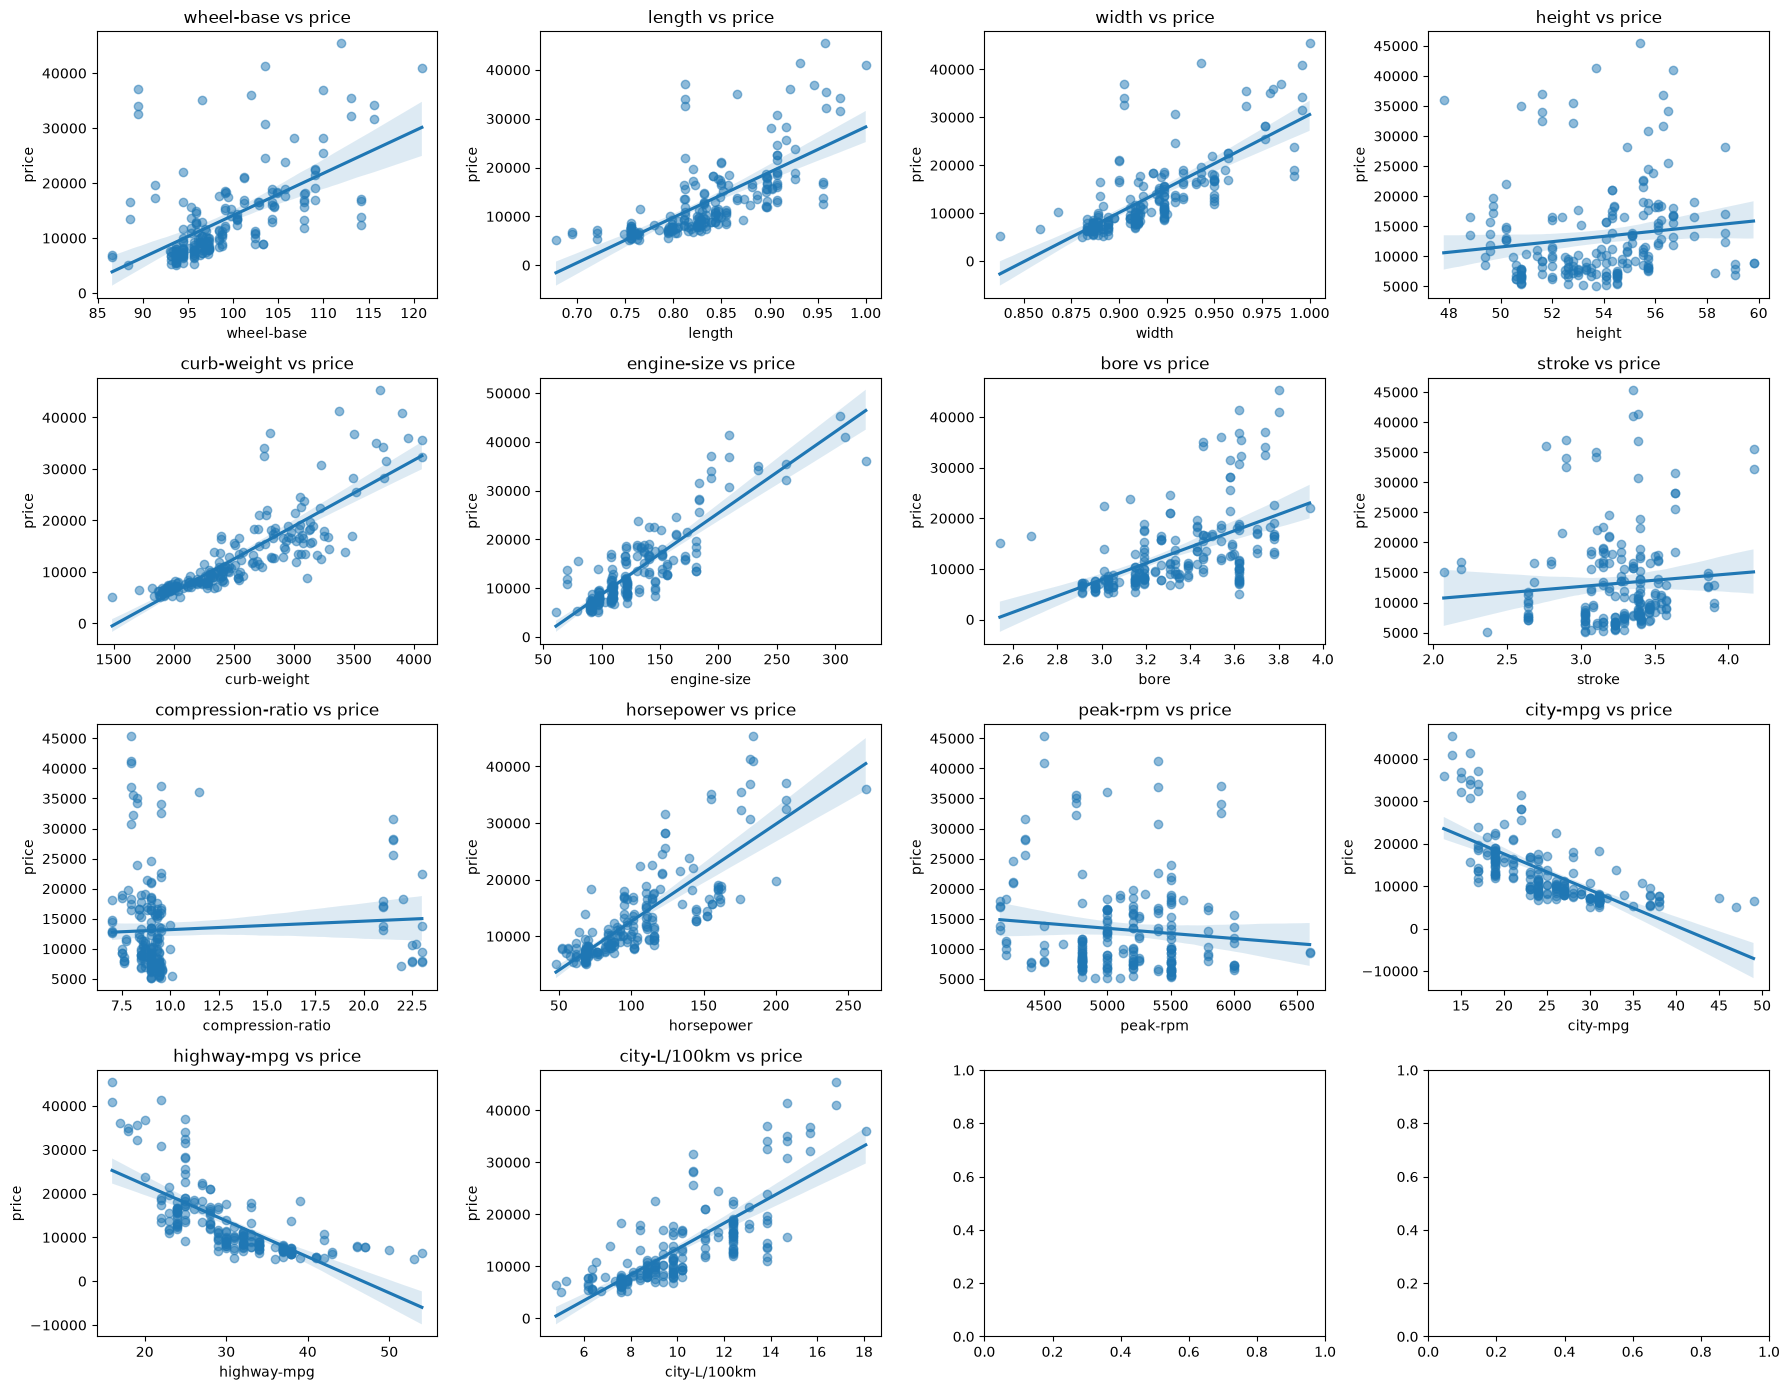

In [157]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.flatten(), continuous):
    sns.regplot(x=col, y="price", data=df, ax=ax, scatter_kws={"alpha": 0.5})
    ax.set_title(f"{col} vs price")
plt.tight_layout()
plt.show()

**Intepretation for correlation**
* Strong positive:  engine-size (0.87), curb-weight (0.83) and horsepower (0.81) have the strongest relationships with price. Bigger, heavier, more powerful cars cost more. city-L/100km (0.79) is positive because higher fuel consumption goes with bigger engines.

* Negative:  city-mpg (-0.69) and highway-mpg (-0.70) are negatively correlated. Cars that are more fuel efficient tend to be cheaper, because they are usually small cars with small engines.

* Moderate:  width, length, wheel-base and bore show moderate to strong positive relationships (0.54 to 0.75), reflecting that larger cars cost more.

* Weak:  compression-ratio, stroke, peak-rpm, height and normalized-losses have correlations near zero (between -0.10 and 0.14) and p-values above 0.05, so there is no statistically significant linear relationship with price.

In [158]:
from scipy import stats #use the pearson test

results = []
for col in continuous:
    r, p = stats.pearsonr(df[col], df["price"])
    results.append([col, round(r, 2), p])

pd.DataFrame(results, columns=["variable", "pearson_r", "p_value"]).sort_values("pearson_r", key=abs, ascending=False)

,variable,pearson_r,p_value
5,engine-size,0.87,9.265492e-64
4,curb-weight,0.83,2.189577e-53
9,horsepower,0.81,6.369057e-48
13,city-L/100km,0.79,3.903106e-44
2,width,0.75,9.200336e-38
12,highway-mpg,-0.70,1.749547e-31
1,length,0.69,8.016477e-30
11,city-mpg,-0.69,2.321132e-29
0,wheel-base,0.58,8.076488e-20
6,bore,0.54,8.049189e-17


General form (for each continuous variable X)

	•	H₀ (null): There is no linear relationship between X and price. The population correlation is zero (ρ = 0).
	•	H₁ (alternative): There is a linear relationship between X and price (ρ ≠ 0).

Significance level: α = 0.05

Decision rule:

	•	If p < 0.05, reject H₀. The relationship is statistically significant.
	•	If p ≥ 0.05, fail to reject H₀. There is no evidence of a relationship.

**Conclusions to write after the test**

Reject H₀ for engine-size, curb-weight, horsepower, city-L/100km, width, highway-mpg, length, city-mpg, wheel-base and bore (all p < 0.05). There is significant evidence that each is linearly related to price.

Fail to reject H₀ for height (p = 0.055), normalized-losses (p = 0.058), peak-rpm (p = 0.15), stroke (p = 0.25) and compression-ratio (p = 0.32). There is not enough evidence of a linear relationship with price.

## 4b. Categorical variables Vs Price

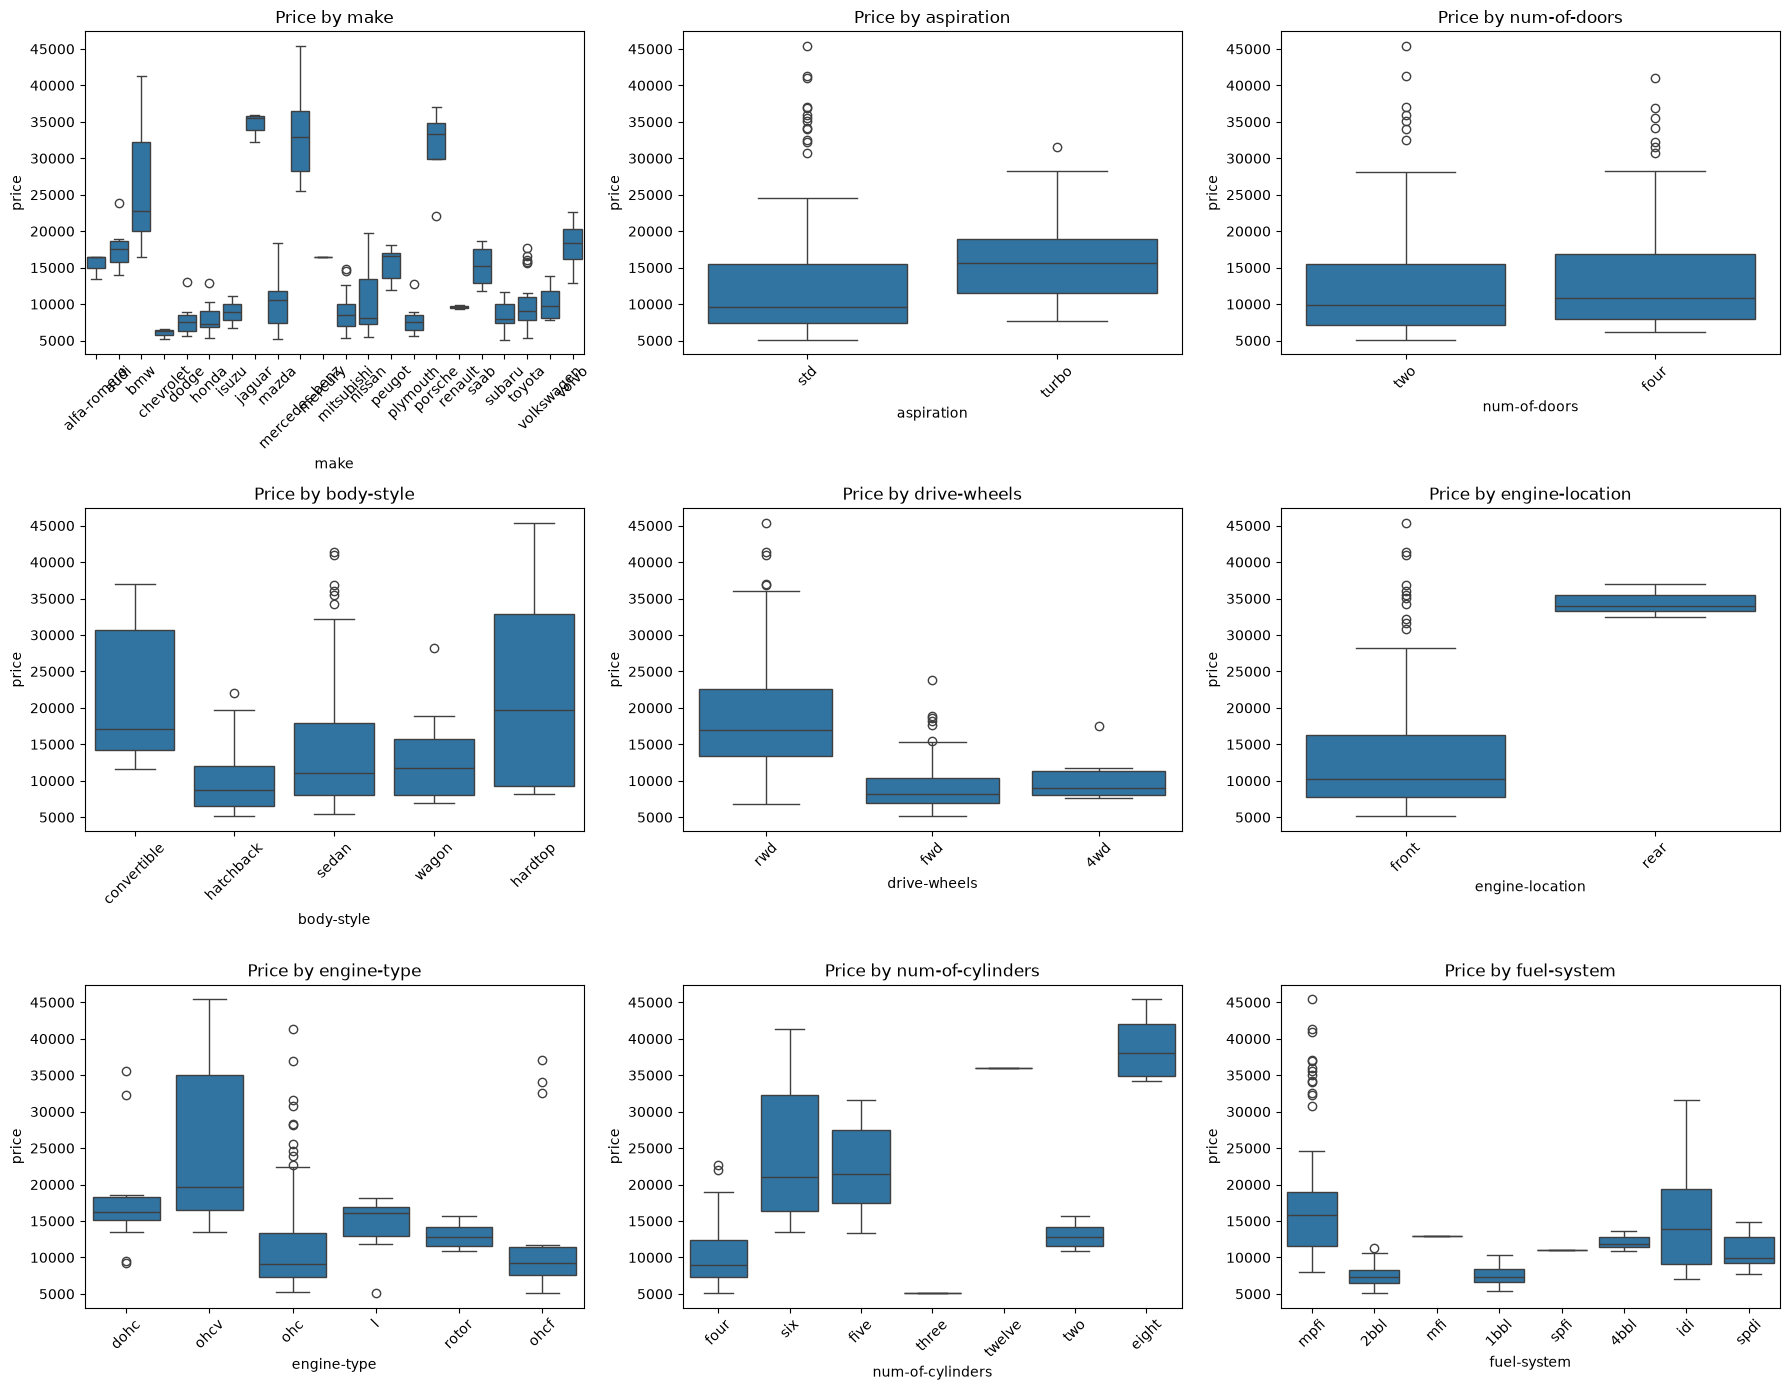

In [159]:
# use box plots
cat_plot = ["make", "aspiration", "num-of-doors", "body-style", "drive-wheels",
            "engine-location", "engine-type", "num-of-cylinders", "fuel-system"]

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.flatten(), cat_plot):
    sns.boxplot(x=col, y="price", data=df, ax=ax)
    ax.set_title(f"Price by {col}")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [160]:
from scipy import stats #ANOVA TEST

cat_tests = ["make", "aspiration", "num-of-doors", "body-style", "drive-wheels",
             "engine-location", "engine-type", "num-of-cylinders", "fuel-system",
             "symboling", "horsepower-binned", "diesel", "gas"]

results = []
for col in cat_tests:
    groups = [g["price"].values for _, g in df.groupby(col) if len(g) >= 2]
    F, p = stats.f_oneway(*groups)

    # eta-squared: share of price variation explained by the category
    grand_mean = df["price"].mean()
    ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
    ss_total = ((df["price"] - grand_mean) ** 2).sum()
    results.append((col, round(F, 1), p, round(ss_between / ss_total, 2)))

anova = pd.DataFrame(results, columns=["variable", "F", "p_value", "eta_squared"])
anova.sort_values("eta_squared", ascending=False)

,variable,F,p_value,eta_squared
0,make,34.9,4.042245e-51,0.80
7,num-of-cylinders,76.3,8.886227e-39,0.58
10,horsepower-binned,108.5,1.520890e-32,0.52
4,drive-wheels,68.0,3.394544e-23,0.41
8,fuel-system,21.0,9.562311e-17,0.35
6,engine-type,9.8,2.086549e-08,0.20
3,body-style,9.1,8.779795e-07,0.16
9,symboling,6.8,6.556746e-06,0.15
5,engine-location,24.5,1.583490e-06,0.11
1,aspiration,6.6,1.074585e-02,0.03


Hypotheses

	•	H₀: The mean price is the same across all categories of the variable.
	•	H₁: At least one category has a different mean price.
	•	α = 0.05

Decision rule:

	•	If p < 0.05, reject H₀. The relationship is statistically significant.
	•	If p ≥ 0.05, fail to reject H₀. There is no evidence of a relationship.


    

**Conclusions to write after the test**

Reject H₀ for make, num-of-cylinders, horsepower-binned, drive-wheels, fuel-system, engine-type, body-style, symboling, engine-location and aspiration (p < 0.05): mean price differs significantly across their categories. Make is the strongest, explaining about 80% of the price variation, followed by number of cylinders (58%), horsepower band (52%) and drive-wheels (41%). The boxplots agree: luxury makes and larger cylinder counts sit far higher, and rwd cars are priced well above fwd.

Fail to reject H₀ for num-of-doors (p = 0.55) and fuel type, diesel/gas (p = 0.12): there's no evidence that the number of doors or the fuel type changes the average price.

## 4c. Two Categorical variables

In [161]:
# use contigency tables
ct = pd.crosstab(df["drive-wheels"], df["body-style"])
ct

body-style,convertible,hardtop,hatchback,sedan,wagon
drive-wheels,,,,,
4wd,0,0,1,3,4
fwd,1,1,49,55,12
rwd,5,7,18,36,9


In [162]:
# Row percentages: within each drive type, what share is each body style?
pd.crosstab(df["drive-wheels"], df["body-style"], normalize="index").round(2) * 100

body-style,convertible,hardtop,hatchback,sedan,wagon
drive-wheels,,,,,
4wd,0.0,0.0,12.0,38.0,50.0
fwd,1.0,1.0,42.0,47.0,10.0
rwd,7.0,9.0,24.0,48.0,12.0


In [163]:
#Chi-square test and Cramér's V
chi2, p, dof, expected = stats.chi2_contingency(ct)
n = ct.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

print(f"Chi-square = {chi2:.1f}, df = {dof}, p-value = {p:.4f}")
print(f"Cramér's V = {cramers_v:.2f}")
print("Cells with expected count < 5:", (expected < 5).sum(), "of", expected.size)

Chi-square = 29.1, df = 8, p-value = 0.0003
Cramér's V = 0.27
Cells with expected count < 5: 9 of 15


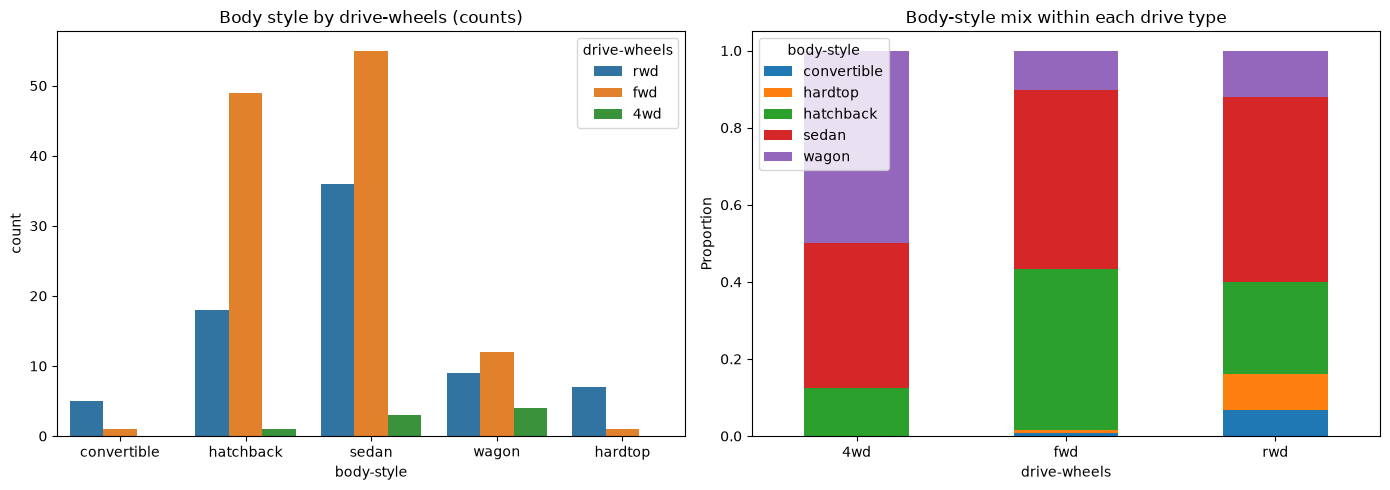

In [164]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x="body-style", hue="drive-wheels", data=df, ax=axes[0])
axes[0].set_title("Body style by drive-wheels (counts)")

pd.crosstab(df["drive-wheels"], df["body-style"], normalize="index").plot(
    kind="bar", stacked=True, ax=axes[1])
axes[1].set_title("Body-style mix within each drive type")
axes[1].set_ylabel("Proportion")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Hypotheses

	•	H₀: Drive-wheels and body-style are independent (no association).
	•	H₁: Drive-wheels and body-style are associated.
	•	α = 0.05

The chi-square test gives p ≈ 0.0003, which is below 0.05, so I reject H₀: drive-wheels and body-style are associated. Cramér's V of about 0.27 indicates a moderate association. Front-wheel drive is concentrated in hatchbacks and sedans, while rear-wheel drive accounts for nearly all convertibles and hardtops. This links to Question 3: the premium body styles (hardtop and convertible) are almost always rear-wheel drive, which helps explain why rwd and those styles both show the highest prices. The two variables therefore partly overlap in their effect on price.    

## Question 5

Prepare the data

Models need numbers, so we one-hot encode the categorical columns. I drop three columns that would double-count information: horsepower-binned (derived from horsepower), city-L/100km (city-mpg in other units) and gas (mirror of diesel).

In [165]:

y = df["price"]
X = df.drop(columns=["price", "horsepower-binned", "city-L/100km", "gas"])

cat_cols = X.select_dtypes(exclude="number").columns.tolist()
X_enc = pd.get_dummies(X, columns=cat_cols, drop_first=True).astype(float)
X_enc.shape

(201, 64)

**Method 1: Random Forest feature importance**

In [166]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=300, random_state=42)
rf.fit(X_enc, y)

imp = pd.Series(rf.feature_importances_, index=X_enc.columns).sort_values(ascending=False)
imp.head(10).round(3)

engine-size          0.649
curb-weight          0.201
highway-mpg          0.051
width                0.015
horsepower           0.013
make_bmw             0.007
normalized-losses    0.007
city-mpg             0.007
length               0.006
wheel-base           0.006
dtype: float64

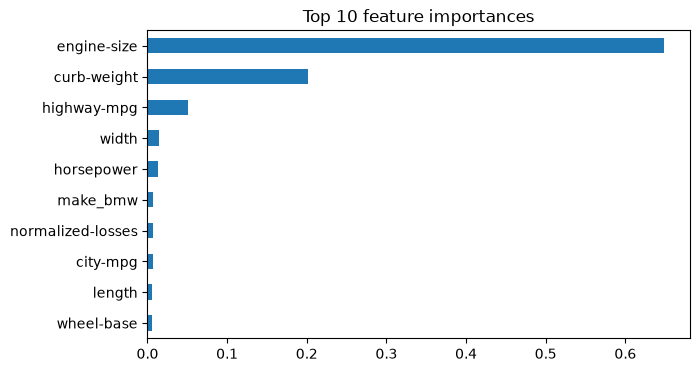

In [167]:
imp.head(10).sort_values().plot(kind="barh", figsize=(7, 4), title="Top 10 feature importances")
plt.show()

**Method 2: Mutual Information(numeric features)**

Mutual Information measures any dependence on price, linear or not, so it complements Pearson correlation.

In [168]:
from sklearn.feature_selection import mutual_info_regression

num = X.select_dtypes("number")
mi = pd.Series(mutual_info_regression(num, y, random_state=42),
               index=num.columns).sort_values(ascending=False)
mi.head(8).round(2)

curb-weight    0.90
highway-mpg    0.85
engine-size    0.84
horsepower     0.84
city-mpg       0.75
width          0.67
wheel-base     0.59
length         0.58
dtype: float64

In [169]:
#check that the selected features are enough
from sklearn.model_selection import cross_val_score, KFold

kf = KFold(5, shuffle=True, random_state=42)
top5 = ["engine-size", "curb-weight", "highway-mpg", "width", "horsepower"]

print("All features:", cross_val_score(rf, X_enc, y, cv=kf, scoring="r2").mean().round(2))
print("Top 5 only:  ", cross_val_score(rf, X_enc[top5], y, cv=kf, scoring="r2").mean().round(2))

All features: 0.88
Top 5 only:   0.88


**Conclusion**

Two feature selection methods were used. Random Forest importance ranks engine-size (0.65) and curb-weight (0.20) far above all others, followed by highway-mpg, width and horsepower. 

Mutual information, which also captures non-linear relationships, ranks curb-weight, highway-mpg, engine-size and horsepower highest. The two methods agree on the same core set. A model using only the top 5 features reaches an R² of about 0.88 in 5-fold cross-validation, the same as using all features, so these five variables capture nearly all the price information.

Main variables: engine-size, curb-weight, horsepower and highway-mpg (continuous), with width as a supporting variable. Among categorical variables, make (η² ≈ 0.80), number of cylinders (0.58) and drive-wheels (0.41) showed the strongest effects in the ANOVA.

Engine-size, curb-weight and horsepower are highly correlated with each other, so importance is shared between them. Their individual scores should not be read as independent effects. Also, highway-mpg is mostly a stand-in for car size (small cars are economical and cheap), not a direct cause of price.

# Recommendation for a car dealer setting prices

1.	**Price mainly by engine size and weight.** Engine-size and curb-weight are the strongest predictors of price (correlations of 0.87 and 0.83, and together about 85% of Random Forest importance). Larger, heavier cars with bigger engines justify a higher price, and horsepower adds to that.

2.	**Adjust for make and drivetrain.** Luxury makes (Jaguar, Mercedes-Benz, Porsche, BMW) average over 26,000, while economy makes (Chevrolet, Dodge, Plymouth) average under 8,000. Rear-wheel-drive cars average about 19,758 against about 9,245 for front-wheel drive, so price rwd cars and premium body styles (hardtop, convertible) as higher-value stock.

3.	**Price by cylinders.** Four-cylinder cars average about 10,300, six-cylinder about 23,700 and eight-cylinder about 38,900.

4.	**Fuel economy signals a cheaper segment.** Cars with high highway-mpg tend to be smaller and cheaper, so use it as a signal of the segment, not as a price driver in itself.

5.	Don't price on the number of doors, fuel type, height, stroke, compression ratio or peak-rpm. These showed no significant relationship with price.
	
6.	**Use medians and watch small groups.** Price is right-skewed, so a typical price is better described by the median than the mean. Groups with very few cars (4wd, convertibles, rear-engine cars) have unreliable averages.

**Limitation:** these results show association, not causation, and the data has only 201 cars, so use them as a pricing guide and not a strict formula.